In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
X1, y1 = make_blobs(n_samples=100, centers=[(2, 2)], cluster_std=0.3, random_state=42)
X2, y2 = make_blobs(n_samples=100, centers=[(6, 6)], cluster_std=0.7, random_state=42)
X3, y3 = make_blobs(n_samples=100, centers=[(10, 2)], cluster_std=1.0, random_state=42)

X = np.vstack((X1, X2, X3))
y = np.concatenate((y1, y2, y3))

noise = np.random.uniform(0, 12, (30, 2))
X = np.vstack((X, noise))
y = np.concatenate((y, [-1] * 30))

df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
print(df.head())
print("Dataset shape:", df.shape)

   Feature1  Feature2
0  2.141971  1.978151
1  1.748235  1.907236
2  1.424369  1.992046
3  1.856248  1.944302
4  1.707595  2.236125
Dataset shape: (330, 2)


In [3]:
model = DBSCAN(eps=0.6, min_samples=5)

df['Cluster'] = model.fit_predict(X)

print(df)
print("Clusters:", set(df['Cluster']))

     Feature1   Feature2  Cluster
0    2.141971   1.978151        0
1    1.748235   1.907236        0
2    1.424369   1.992046        0
3    1.856248   1.944302        0
4    1.707595   2.236125        0
..        ...        ...      ...
325  0.518319   6.574804       -1
326  1.697365   7.453438       -1
327  6.171125  10.455002       -1
328  7.299545   4.703705        1
329  8.327423   7.677634       -1

[330 rows x 3 columns]
Clusters: {0, 1, 2, -1}


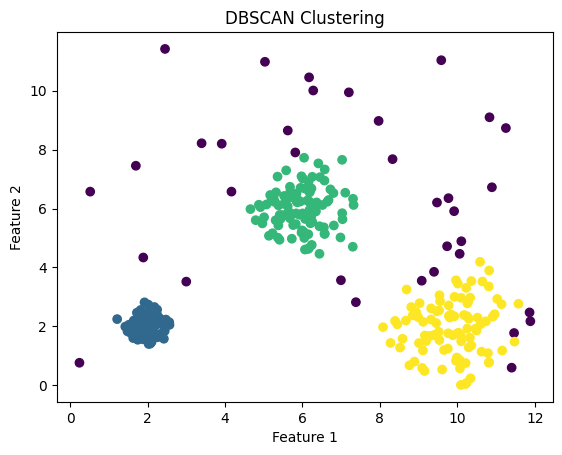

In [4]:
plt.scatter(df['Feature1'], df['Feature2'],
            c=df['Cluster'], cmap='viridis')

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [5]:
labels = df['Cluster']

if len(set(labels) - {-1}) > 1:
    score = silhouette_score(X[labels != -1], labels[labels != -1])
    print("Silhouette Score:", score)

print("Adjusted Rand Index:", adjusted_rand_score(y, labels))

Silhouette Score: 0.8077074558828329
Adjusted Rand Index: 0.0935469887568465
